In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from functools import partial
import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import toy_network

import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import operator
from jax import config
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os
import statistics

from matplotlib.colors import CenteredNorm
import scipy.stats as stats
# from scipy.stats import norm
from cmfa.emu_example import ordered_ilr_func, closure

In [2]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

In [3]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"
PLOT_DIR = Path("..") / "figures"

simulated_id = jnp.load(RESULTS_DIR / "id_simulated_reference.npy")

with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)

with open(RESULTS_DIR / "estimated_fluxes_sd_reference.pkl", "rb") as f:
    estimated_fluxes_sd = pickle.load(f)

with open(RESULTS_DIR / "fvalues_reference.pkl", "rb") as f:
    fvals = pickle.load(f)

In [4]:
s1 = 123
s2 = 255
s3 = 919

sim_id = simulated_id[s1]
# sim_ids = np.array([simulated_id[s1],simulated_id[s2],simulated_id[s3]])
# sd = np.std(sim_ids, axis=0)
sd_trad = np.std(simulated_id, axis=0)
sd_ilr = np.std(ordered_ilr_func(simulated_id), axis=0)

flux_est_trad = estimated_fluxes_ref["trad"][s1, [4,5]]
flux_est_ilr = estimated_fluxes_ref["ilr"][s1, [4,5]]

flux_sd_trad = estimated_fluxes_sd["trad"][s1, [4,5]]
flux_sd_ilr = estimated_fluxes_sd["ilr"][s1, [4,5]]

fval_trad = fvals["trad"][s1]
fval_ilr = fvals["ilr"][s1]

In [5]:
def profile_likelihood(loss_function, sd, observation, opt_flux, opt_fval):
    # 1. Setup Data
    weights = 1/sd

    # 3. Create pyPESTO Objective
    # PyPESTO will call this function as objective(x)
    def my_loss_function(x): 
        return loss_function(x, args=(observation, weights))[0] 

    objective = pypesto.Objective(fun=my_loss_function)

    # 4. Define Problem
    problem = pypesto.Problem(
        objective=objective,
        lb=[-6] * 2, 
        ub=[6] * 2,  
        x_names=['v3', 'v5']
    )

    # 5. Manually inject the Optimistix result into pyPESTO
    result = pypesto.Result(problem=problem)
    opt_result_manual = OptimizerResult(
        x=np.array(np.log(opt_flux)),        # Convert JAX to NumPy
        fval=float(np.array(opt_fval[0])),          # Cast JAX scalar to float
        id="optimistix_bfgs",
    )

    # opt_result_manual = OptimizerResult(
    #     x=flux_est,        # Convert JAX to NumPy
    #     fval=fval_est,          # Cast JAX scalar to float
    #     id="optimistix_bfgs",
    # )
    result.optimize_result.append(opt_result_manual)

    # 6. Profile Likelihood
    # pyPESTO will now use Scipy to "walk" the likelihood surface
    result = profile.parameter_profile(
        problem=problem,
        result=result,
        optimizer=pypesto.optimize.ScipyOptimizer(method="L-BFGS-B"),
    )

    result.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result.profile_result.get_profiler_result(0)["x_path"][0])
    result.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result.profile_result.get_profiler_result(1)["x_path"][1])
    
    return result

def fisher_interval(flux_est, flux_sd):
    mu = np.log(flux_est)
    sigma = flux_sd
    x_start = (mu - 2.4 * sigma)
    x_end = (mu + 2.4 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled


In [6]:
result_trad = profile_likelihood(toy_network.loss_trad, sd_trad, sim_id, opt_flux=flux_est_trad, opt_fval=fval_trad)
result_ilr = profile_likelihood(toy_network.loss_ilr, sd_ilr, sim_id, flux_est_ilr, fval_ilr)

100%|██████████| 4/4 [00:09<00:00,  2.38s/it]


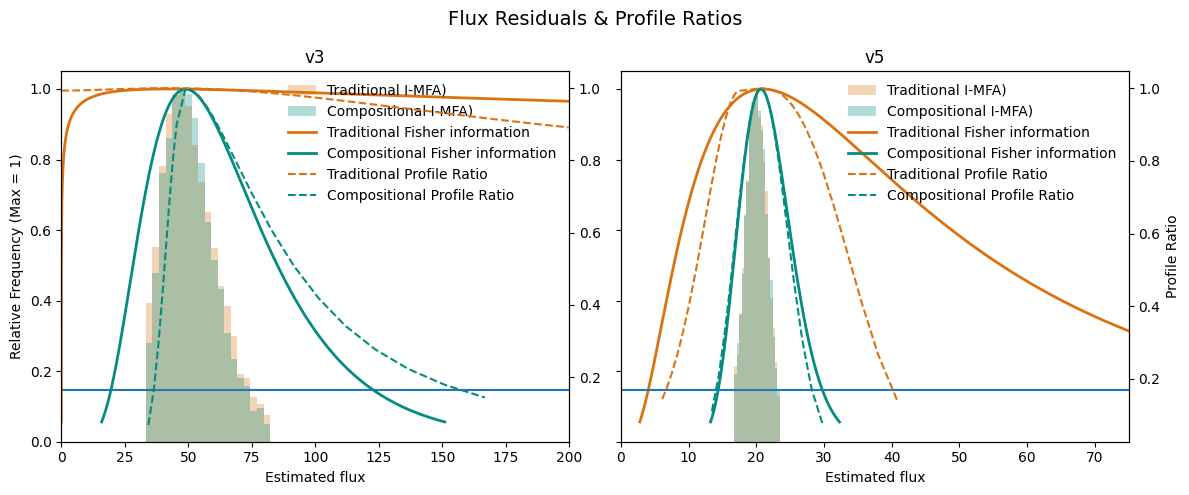

In [7]:
est_trad = estimated_fluxes_ref["trad"][:, [4, 5]]
est_ilr = estimated_fluxes_ref["ilr"][:, [4, 5]]

# Create 1x2 subplots just like your original setup
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    est_trad_i = est_trad[:, i].flatten()
    est_comp_i = est_ilr[:, i].flatten()
    
    xmin = np.quantile(np.concat([est_trad_i, est_comp_i]), 0.025)
    xmax = np.quantile(np.concat([est_trad_i, est_comp_i]), 0.975)
    bins = np.linspace(xmin, xmax, 20)
    
    # 1. Calculate peak-normalization weights for histograms
    counts_trad, _ = np.histogram(est_trad_i, bins=bins)
    counts_ilr, _ = np.histogram(est_comp_i, bins=bins)
    
    weights_trad = np.ones_like(est_trad_i) / np.max(counts_trad)
    weights_ilr = np.ones_like(est_comp_i) / np.max(counts_ilr)
    
    # 2. Plot the Histograms on the left y-axis (ax)
    h_trad = ax.hist(
        est_trad_i, 
        bins=bins,
        weights=weights_trad,
        color=TRAD,
        alpha=0.3,
        label=f"Traditional I-MFA)" 
    )
    h_ilr = ax.hist(
        est_comp_i, 
        bins=bins,
        weights=weights_ilr,
        color=ILR,
        alpha=0.3,
        label=f"Compositional I-MFA)" 
    )
    
    # 3. Create a twin y-axis on the right side for the profile ratio line
    ax_twin = ax.twinx()
    
    # Extract the dynamic paths for the profile lines
    x_path_trad = result_trad.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_trad = result_trad.profile_result.get_profiler_result(i)["ratio_path"]

    # Extract the dynamic paths for the profile lines
    x_path_ilr = result_ilr.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_ilr = result_ilr.profile_result.get_profiler_result(i)["ratio_path"]
    
    # Plot the line (using a distinct color and style so it stands out)
    line = ax_twin.plot(x_path_trad, ratio_path_trad, color=TRAD, linestyle="--", label="Traditional Profile Ratio")
    line = ax_twin.plot(x_path_ilr, ratio_path_ilr, color=ILR, linestyle="--", label="Compositional Profile Ratio")
    
    x_trad, y_trad = fisher_interval(flux_est_trad[i], flux_sd_trad[i])
    ax.plot(x_trad, y_trad, label='Traditional Fisher information', color=TRAD, lw=2)
    
    x_ilr, y_ilr = fisher_interval(flux_est_ilr[i], flux_sd_ilr[i])
    ax.plot(x_ilr, y_ilr, label='Compositional Fisher information', color=ILR, lw=2)

    # 4. Formatting and Labels
    ax.set(title=f"v{3+2*i}", xlabel="Estimated flux")
    
    # Combine legends from both axes so they appear in a single box
    lines_hist, labels_hist = ax.get_legend_handles_labels()
    lines_twin, labels_twin = ax_twin.get_legend_handles_labels()
    ax.legend(lines_hist + lines_twin, labels_hist + labels_twin, frameon=False, loc="upper right")
    
    # Set the right y-axis label only for the rightmost plot to keep it clean
    if i == 1:
        ax_twin.set_ylabel("Profile Ratio")
    else:
        # Optional: Link the right-hand y-axes if you want them to share limits
        pass 

# Set the left y-axis label for the histograms
axes[0].set_ylabel("Relative Frequency (Max = 1)")
axes[0].axhline(0.1465)
axes[1].axhline(0.1465)
axes[0].set_xlim(0,200)
axes[1].set_xlim(0,75)

f.suptitle("Flux Residuals & Profile Ratios", fontsize=14)
f.tight_layout()


[<Axes: xlabel='v3', ylabel='Objective function value'>, <Axes: xlabel='v5'>]

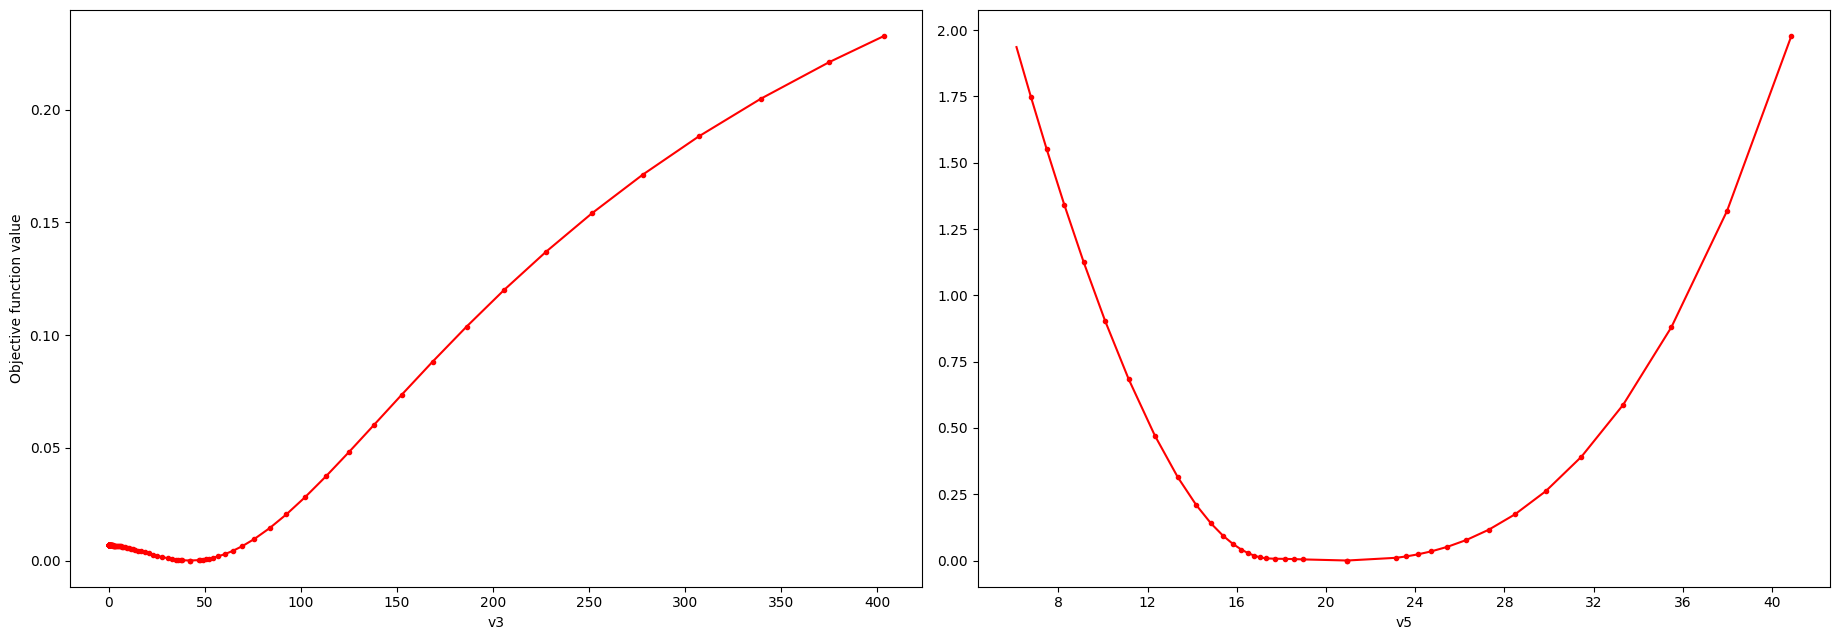

In [8]:
pypesto.visualize.profiles(result_trad, show_bounds=False, plot_objective_values=True)

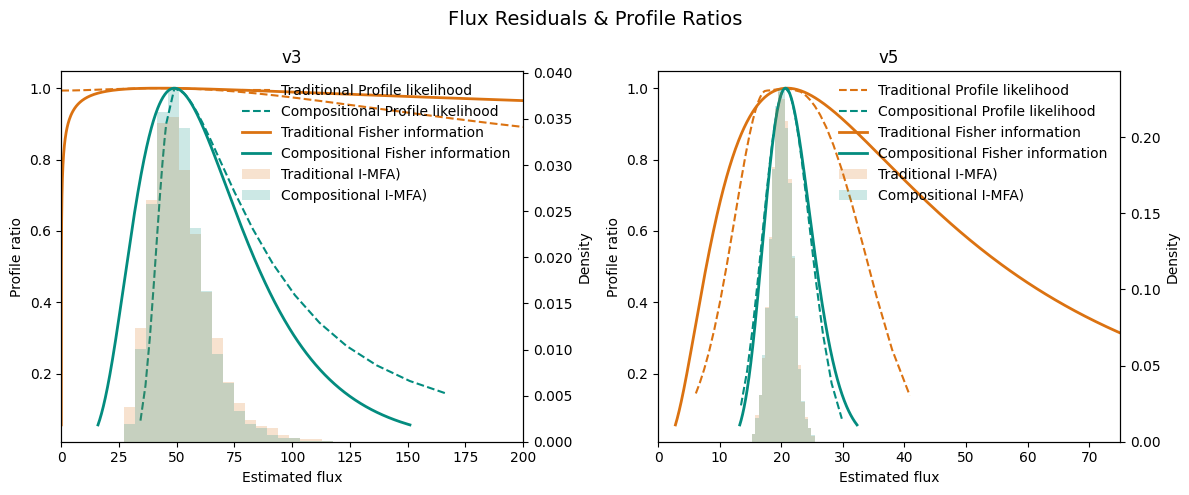

In [9]:
est_trad = estimated_fluxes_ref["trad"][:, [4, 5]]
est_ilr = estimated_fluxes_ref["ilr"][:, [4, 5]]

# Create 1x2 subplots just like your original setup
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=False)

for (i, ax) in enumerate(axes):
        # 3. Create a twin y-axis on the right side for the profile ratio line
    
    
    # Extract the dynamic paths for the profile lines
    x_path_trad = result_trad.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_trad = result_trad.profile_result.get_profiler_result(i)["ratio_path"]

    # Extract the dynamic paths for the profile lines
    x_path_ilr = result_ilr.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_ilr = result_ilr.profile_result.get_profiler_result(i)["ratio_path"]
    
    # Plot the line (using a distinct color and style so it stands out)
    line = ax.plot(x_path_trad, ratio_path_trad, color=TRAD, linestyle="--", label="Traditional Profile likelihood")
    line = ax.plot(x_path_ilr, ratio_path_ilr, color=ILR, linestyle="--", label="Compositional Profile likelihood")
    
    x_trad, y_trad = fisher_interval(flux_est_trad[i], flux_sd_trad[i])
    ax.plot(x_trad, y_trad, label='Traditional Fisher information', color=TRAD, lw=2)
    
    x_ilr, y_ilr = fisher_interval(flux_est_ilr[i], flux_sd_ilr[i])
    ax.plot(x_ilr, y_ilr, label='Compositional Fisher information', color=ILR, lw=2)

    # 4. Formatting and Labels
    ax.set(title=f"v{3+2*i}", xlabel="Estimated flux")

    ax_twin = ax.twinx() 
    est_trad_i = est_trad[:, i].flatten()
    est_comp_i = est_ilr[:, i].flatten()
    
    xmin = np.quantile(np.concat([est_trad_i, est_comp_i]), 0.001)
    xmax = np.quantile(np.concat([est_trad_i, est_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    
    # 2. Plot the Histograms on the left y-axis (ax)
    h_trad = ax_twin.hist(
        est_trad_i,
        bins=bins,
        color=TRAD,
        alpha=0.2,
        density=True,
        label=f"Traditional I-MFA)" 
    )
    h_ilr = ax_twin.hist(
        est_comp_i, 
        bins=bins,
        color=ILR,
        alpha=0.2,
        density=True,
        label=f"Compositional I-MFA)" 
    )
    # 4. Formatting and Labels
        # Set the right y-axis label only for the rightmost plot to keep it clean
    ax_twin.set_ylabel("Density")

    
    # Combine legends from both axes so they appear in a single box
    lines_hist, labels_hist = ax.get_legend_handles_labels()
    lines_twin, labels_twin = ax_twin.get_legend_handles_labels()
    ax.legend(lines_hist + lines_twin, labels_hist + labels_twin, frameon=False, loc="upper right")
    ax.set(title=f"v{3+2*i}", xlabel="Estimated flux")


# Set the left y-axis label for the histograms
axes[0].set_ylabel("Profile ratio")
axes[1].set_ylabel("Profile ratio")

axes[0].set_xlim(0,200)
axes[1].set_xlim(0,75)

f.suptitle("Flux Residuals & Profile Ratios", fontsize=14)
f.tight_layout()


In [55]:
flux_sd_ilr[1]

Array(0.18556537, dtype=float64)

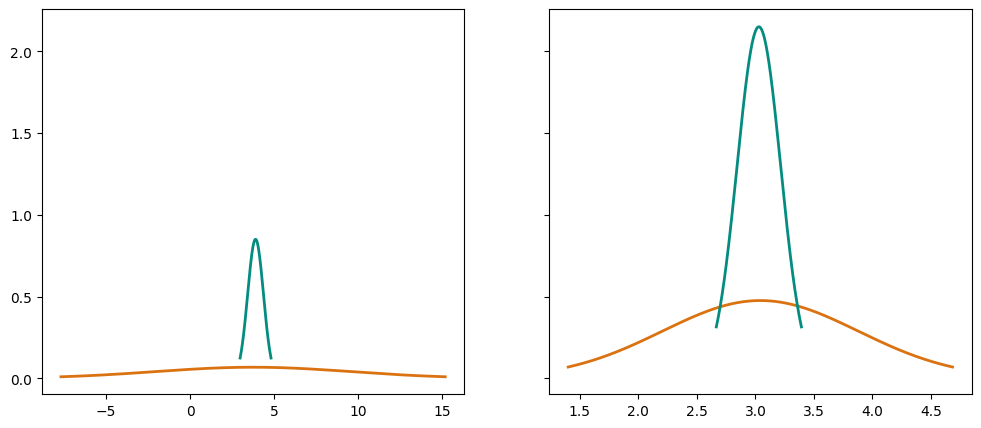

In [103]:
def fisher_interval(flux_est, flux_sd):
    mu = np.log(flux_est)
    sigma = flux_sd
    x_start = (mu - 1.96 * sigma)
    x_end = (mu + 1.96 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw

    return (x_axis), y_scaled

fig, [ax1, ax2] = plt.subplots(1, 2, figsize=[12, 5], sharey=True)
x_trad, y_trad = fisher_interval(flux_est_trad[0], flux_sd_trad[0])
ax1.plot(x_trad, y_trad, label='Traditional Fisher information', color=TRAD, lw=2)

x_ilr, y_ilr = fisher_interval(flux_est_ilr[0], flux_sd_ilr[0])
ax1.plot(x_ilr, y_ilr, label='Compositional Fisher information', color=ILR, lw=2)

x_trad, y_trad = fisher_interval(flux_est_trad[1], flux_sd_trad[1])
ax2.plot(x_trad, y_trad, label='Traditional Fisher information', color=TRAD, lw=2)

x_ilr, y_ilr = fisher_interval(flux_est_ilr[1], flux_sd_ilr[1])
ax2.plot(x_ilr, y_ilr, label='Compositional Fisher information', color=ILR, lw=2)

In [95]:
sort_idx = np.argsort(param_values)
x_profile = param_values[sort_idx]
y_ratios = likelihood_ratios[sort_idx]

# 4. Normalize the profile to behave like a density curve
# The area underneath the curve must equal 1 to match the density histogram
total_area = simpson(y=y_ratios, x=x_profile)
y_density = y_ratios / total_area

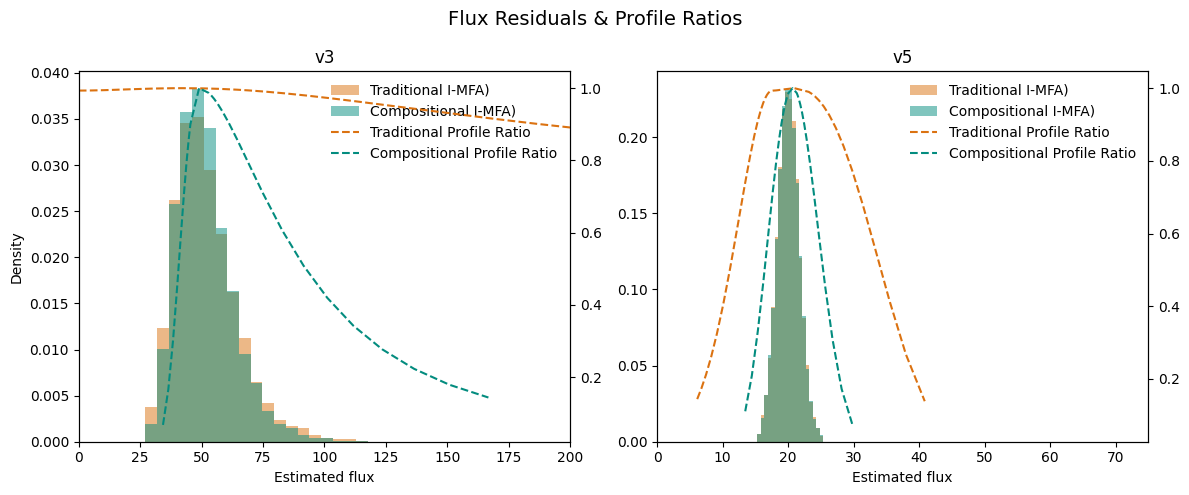

In [76]:
est_trad = estimated_fluxes_ref["trad"][:, [4, 5]]
est_ilr = estimated_fluxes_ref["ilr"][:, [4, 5]]
from scipy.integrate import simpson

# Create 1x2 subplots just like your original setup
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=False)

for (i, ax) in enumerate(axes):
    est_trad_i = est_trad[:, i].flatten()
    est_comp_i = est_ilr[:, i].flatten()
    
    xmin = np.quantile(np.concat([est_trad_i, est_comp_i]), 0.001)
    xmax = np.quantile(np.concat([est_trad_i, est_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    
    # 2. Plot the Histograms on the left y-axis (ax)
    h_trad = ax.hist(
        est_trad_i,
        bins=bins,
        color=TRAD,
        alpha=0.5,
        density=True,
        label=f"Traditional I-MFA)" 
    )
    h_ilr = ax.hist(
        est_comp_i, 
        bins=bins,
        color=ILR,
        alpha=0.5,
        density=True,
        label=f"Compositional I-MFA)" 
    )
    # 4. Formatting and Labels
    ax.set(title=f"v{3+2*i}", xlabel="Estimated flux")
        # 3. Create a twin y-axis on the right side for the profile ratio line
    ax_twin = ax.twinx()
    
    # Extract the dynamic paths for the profile lines
    x_path_trad = result_trad.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_trad = result_trad.profile_result.get_profiler_result(i)["ratio_path"]

    # Extract the dynamic paths for the profile lines
    x_path_ilr = result_ilr.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_ilr = result_ilr.profile_result.get_profiler_result(i)["ratio_path"]

    sort_idx = np.argsort(x_path_ilr)
    x_profile = x_path_ilr[sort_idx]
    y_ratios = ratio_path_ilr[sort_idx]

    # 4. Normalize the profile to behave like a density curve
    # The area underneath the curve must equal 1 to match the density histogram
    total_area = simpson(y=y_ratios, x=x_profile)
    y_density = y_ratios / total_area
    
    # Plot the line (using a distinct color and style so it stands out)
    line = ax_twin.plot(x_path_trad, ratio_path_trad, color=TRAD, linestyle="--", label="Traditional Profile Ratio")
    line = ax_twin.plot(x_path_ilr, ratio_path_ilr, color=ILR, linestyle="--", label="Compositional Profile Ratio")

    # 4. Formatting and Labels
    ax.set(title=f"v{3+2*i}", xlabel="Estimated flux")
    
    # Combine legends from both axes so they appear in a single box
    lines_hist, labels_hist = ax.get_legend_handles_labels()
    lines_twin, labels_twin = ax_twin.get_legend_handles_labels()
    ax.legend(lines_hist + lines_twin, labels_hist + labels_twin, frameon=False, loc="upper right")

    

# Set the left y-axis label for the histograms
axes[0].set_ylabel("Density")

axes[0].set_xlim(0,200)
axes[1].set_xlim(0,75)

f.suptitle("Flux Residuals & Profile Ratios", fontsize=14)
f.tight_layout()
